# **Práctica 4: Ensambles**
### Introducción a la Ciencia de Datos
*Alumno: Norman O. Guzmán Chaboya*

En esta práctica se mide cuánto ganan los ensambles sobre los cinco clasificadores base obtenidos en la práctica anterior (árbol de decisión, Naive Bayes, kNN, SVM y regresión logística) cuando estos ya están bien ajustados. Se utiliza el conjunto de deserción estudiantil, con el mismo preprocesamiento, los mismos hiperparámetros y los mismos cinco pliegues estratificados de la práctica 3. Después, se busca el mejor modelo para el conjunto de datos de Bank Marketing.

A lo largo del notebook se realiza lo siguiente:

1. Datos
2. Varianza
3. Sesgo
4. Combinación de los cinco modelos base
5. Bagging optimizado
6. Boosting optimizado
7. Comparación de todos los modelos
8. Bank Marketing: datos y protocolo
9. Búsqueda del mejor modelo
10. Comparación
11. Modelo final
12. Conclusiones

In [1]:
import os
import warnings
import joblib
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
plt.style.use('bmh')
import sklearn
import lightgbm
import catboost
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, TunedThresholdClassifierCV, cross_validate
from sklearn.metrics import ConfusionMatrixDisplay, f1_score
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import BernoulliNB, ComplementNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier, ExtraTreesClassifier, RandomForestClassifier,
                              StackingClassifier, VotingClassifier)
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

ran = 42

# staged_predict de AdaBoost y LightGBM reciben los datos sin nombres de columnas, y scikit-learn lo avisa en cada
# llamada. Es interno y no cambia los resultados.
warnings.filterwarnings('ignore', message='X does not have valid feature names')

## Parte 1. Deserción estudiantil

## 1. Datos y modelos base

Se recuperan los datos, los atributos conocidos al cierre del primer semestre y el preprocesamiento anteriormente realizados:

In [2]:
entrena = pd.read_csv('data/desercion-entrenamiento.csv')
entrena['Target'] = entrena['Target'].str.lower()

cols_nominales = ['Marital status', 'Application mode', 'Course', 'Previous qualification', 'Nacionality',
                  "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
cols_binarias = ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor',
                 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
cols_ordinales = ['Application order']
cols_macro = ['Unemployment rate', 'Inflation rate', 'GDP']
cols_1s = [c for c in entrena.columns if '1st sem' in c]
cols_numericas = ['Previous qualification (grade)', 'Admission grade', 'Age at enrollment'] + cols_1s + cols_macro
atributos = cols_nominales + cols_binarias + cols_ordinales + cols_numericas

X, y = entrena[atributos], entrena['Target']
orden_clases = ['dropout', 'enrolled', 'graduate']
print(f"{X.shape[0]} estudiantes, {X.shape[1]} atributos | clases: {y.value_counts().reindex(orden_clases).to_dict()}")

3539 estudiantes, 30 atributos | clases: {'dropout': 1137, 'enrolled': 635, 'graduate': 1767}


In [3]:
MIN_FREC = 0.01 # Proporción mínima de estudiantes para que una categoría se conserve por separado

def onehot():
    return OneHotEncoder(min_frequency=MIN_FREC, handle_unknown='infrequent_if_exist', sparse_output=False)

def preparar(numericos, cols_num=cols_ordinales + cols_numericas):
    return ColumnTransformer([('nominales', onehot(), cols_nominales),
                              ('binarios', 'passthrough', cols_binarias),
                              ('numericos', numericos, cols_num)])

def pipeline_arbol(**params):
    return Pipeline([('prep', preparar('passthrough')), ('modelo', DecisionTreeClassifier(random_state=ran, **params))])

warnings.filterwarnings('ignore', message='Bins whose width are too small')
warnings.filterwarnings('ignore', message='Feature .* is constant')
variantes_nb = {'bernoulli': BernoulliNB, 'multinomial': MultinomialNB, 'complement': ComplementNB}

def pipeline_nb(variante='bernoulli', n_bins=5, alpha=1.0):
    intervalos = KBinsDiscretizer(n_bins=n_bins, encode='onehot-dense', strategy='quantile', quantile_method='averaged_inverted_cdf')
    return Pipeline([('prep', preparar(intervalos)), ('modelo', variantes_nb[variante](alpha=alpha))])

def pipeline_knn(**params):
    return Pipeline([('prep', preparar(StandardScaler())), ('modelo', KNeighborsClassifier(**params))])

def pipeline_svm(**params):
    return Pipeline([('prep', preparar(StandardScaler())), ('modelo', SVC(random_state=ran, **params))])

def pipeline_logistica(**params):
    modelo = LogisticRegression(solver='saga', tol=1e-3, max_iter=5000, random_state=ran, **params)
    return Pipeline([('prep', preparar(StandardScaler())), ('modelo', modelo)])

Los cinco clasificadores base se construyen con los mejores hiperparámetros de la práctica 3 y se evalúan con los mismos pliegues:

In [4]:
pliegues = StratifiedKFold(n_splits=5, shuffle=True, random_state=ran)

config_p3 = {
    'Árbol de decisión': dict(criterion='entropy', max_depth=9, min_samples_leaf=17, ccp_alpha=0.000177, class_weight='balanced'),
    'Naive Bayes': dict(variante='bernoulli', n_bins=8, alpha=0.00419),
    'kNN': dict(n_neighbors=8, weights='uniform', p=1),
    'SVM': dict(kernel='rbf', C=10.2, gamma=0.00407, class_weight='balanced'),
    'Regresión logística': dict(C=0.0953, l1_ratio=0.311, class_weight='balanced'),
}
fabricas = {'Árbol de decisión': pipeline_arbol, 'Naive Bayes': pipeline_nb, 'kNN': pipeline_knn,
            'SVM': pipeline_svm, 'Regresión logística': pipeline_logistica}
modelos_base = {nombre: fabricas[nombre](**config_p3[nombre]) for nombre in fabricas}

def formato(params):
    return ', '.join(f"{k.split('__')[-1]}={v:.3g}" if isinstance(v, float) else f"{k.split('__')[-1]}={v}"
                     for k, v in params.items())

def evaluar(modelo, configuracion=''):
    # F1 macro por pliegue, tiempo de entrenamiento y predicciones de validación (cada estudiante, con el modelo que no lo vio)
    r = cross_validate(modelo, X, y, cv=pliegues, scoring='f1_macro', return_train_score=True,
                       return_estimator=True, return_indices=True)
    pred = np.empty(len(y), dtype=object)
    for est, i_val in zip(r['estimator'], r['indices']['test']):
        pred[i_val] = np.ravel(est.predict(X.iloc[i_val]))
    return {'F1 macro': r['test_score'].mean(), 'desv. est.': r['test_score'].std(),
            'F1 entrenamiento': r['train_score'].mean(),
            'sensibilidad enrolled': (pred[y == 'enrolled'] == 'enrolled').mean(),
            'entrenamiento (s)': r['fit_time'].mean(), 'configuración': configuracion, 'pred': pred}

def tabla(nombres):
    columnas = ['F1 macro', 'desv. est.', 'F1 entrenamiento', 'sensibilidad enrolled', 'entrenamiento (s)']
    return pd.DataFrame({n: resultados[n] for n in nombres}).T[columnas].astype(float).round(3)

resultados = {nombre: evaluar(modelo, formato(config_p3[nombre])) for nombre, modelo in modelos_base.items()}
tabla(modelos_base)

,F1 macro,desv. est.,F1 entrenamiento,sensibilidad enrolled,entrenamiento (s)
Árbol de decisión,0.642,0.007,0.707,0.580,0.031
Naive Bayes,0.621,0.009,0.641,0.419,0.034
kNN,0.579,0.012,0.673,0.224,0.030
SVM,0.683,0.008,0.736,0.609,0.561
Regresión logística,0.682,0.010,0.709,0.570,0.399


Los cinco clasificadores reproducen los resultados de la práctica 3. El SVM (0.683) y la regresión logística (0.682) son los mejores, seguidos del árbol de decisión (0.642), Naive Bayes (0.621) y kNN (0.579). El SVM es también el que mejor reconoce a los estudiantes inscritos (sensibilidad de 0.609), mientras que kNN, el único sin pesos por clase, reconoce apenas a 22% de ellos. Estos cinco modelos son la referencia contra la que se mide cada ensamble.

## 2. Varianza: árbol sin límite y bagging

Un árbol sin límite de profundidad memoriza el entrenamiento y cambia mucho con cualquier cambio en los datos: su varianza es alta. Bagging entrena árboles como ese en muestras bootstrap y los hace votar. Para la curva, en cada pliegue se agregan árboles progresivamente con `warm_start=True` y se mide el F1 macro con 1 a 400 árboles:

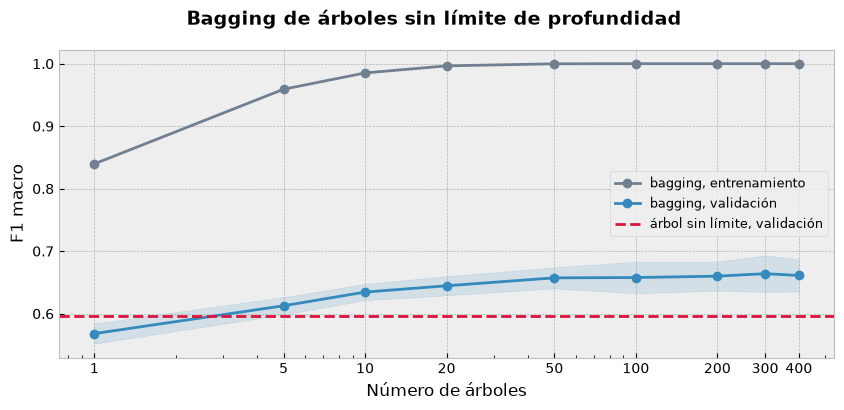

,F1 macro,desv. est.,F1 entrenamiento,sensibilidad enrolled,entrenamiento (s)
Árbol sin límite,0.596,0.005,1.0,0.364,0.064
Bagging,0.661,0.026,1.0,0.326,1.144


In [5]:
N_ARBOLES = [1, 5, 10, 20, 50, 100, 200, 300, 400]
arbol_completo = pipeline_arbol()
bagging = Pipeline([('prep', preparar('passthrough')),
                    ('modelo', BaggingClassifier(DecisionTreeClassifier(random_state=ran), warm_start=True,
                                                 random_state=ran, n_jobs=-1))])

curva_bag = {'entrenamiento': [], 'validación': []}
for i_ent, i_val in pliegues.split(X, y):
    modelo, entr, val = clone(bagging), [], []
    for n in N_ARBOLES:
        modelo.set_params(modelo__n_estimators=n).fit(X.iloc[i_ent], y.iloc[i_ent])   # solo se agregan los árboles nuevos
        entr.append(f1_score(y.iloc[i_ent], modelo.predict(X.iloc[i_ent]), average='macro'))
        val.append(f1_score(y.iloc[i_val], modelo.predict(X.iloc[i_val]), average='macro'))
    curva_bag['entrenamiento'].append(entr)
    curva_bag['validación'].append(val)

resultados['Árbol sin límite'] = evaluar(arbol_completo, 'max_depth=None')
resultados['Bagging'] = evaluar(clone(bagging).set_params(modelo__n_estimators=400), '400 árboles sin límite')

val_bag = np.array(curva_bag['validación'])
with plt.style.context('bmh'):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(N_ARBOLES, np.mean(curva_bag['entrenamiento'], axis=0), color='slategrey', marker='o', label='bagging, entrenamiento')
    ax.plot(N_ARBOLES, val_bag.mean(axis=0), color='#348ABD', marker='o', linewidth=2, label='bagging, validación')
    ax.fill_between(N_ARBOLES, val_bag.mean(axis=0) - val_bag.std(axis=0), val_bag.mean(axis=0) + val_bag.std(axis=0),
                    color='#348ABD', alpha=0.15)
    ax.axhline(resultados['Árbol sin límite']['F1 macro'], color='crimson', linestyle='--', label='árbol sin límite, validación')
    ax.set_xscale('log')
    ax.set_xticks(N_ARBOLES, N_ARBOLES)
    ax.set_xlabel('Número de árboles')
    ax.set_ylabel('F1 macro')
    ax.legend(loc='center right', fontsize=9)
    fig.suptitle('Bagging de árboles sin límite de profundidad', fontweight='bold', fontsize=14)
    plt.show()

tabla(['Árbol sin límite', 'Bagging'])

El árbol sin límite clasifica perfectamente el entrenamiento, pero en validación obtiene 0.596, por debajo del árbol podado de la práctica 3 (0.642). Con bagging, desde 5 árboles se supera al árbol completo, la ganancia es rápida hasta 50 árboles (0.657) y después la curva se estabiliza alrededor de 0.66 (0.661 con 400). El F1 de entrenamiento se mantiene en 1, de modo que cada árbol sigue memorizando su muestra: bagging no reduce el sesgo, sino la varianza. Los errores de un árbol sin límite dependen mucho de la muestra con la que se entrenó, y al promediar árboles entrenados con muestras bootstrap distintas, esos errores se cancelan en parte. La mejora se detiene porque los árboles no son independientes: comparten los mismos atributos dominantes, y esa correlación es el límite de lo que el promedio puede reducir. Sin pesos por clase, bagging reconoce solo a 33% de los inscritos.

## 3. Sesgo: tocón y AdaBoost

Un tocón (árbol de profundidad 1) hace una sola pregunta y no alcanza a representar el problema: su sesgo es alto. AdaBoost suma tocones en secuencia, cada uno enfocado en los estudiantes que los anteriores clasificaron mal. Con `staged_predict` se obtienen las predicciones después de cada una de las 400 rondas; como un `Pipeline` no tiene ese método, primero se transforman los datos con el preprocesamiento ajustado en el pliegue:

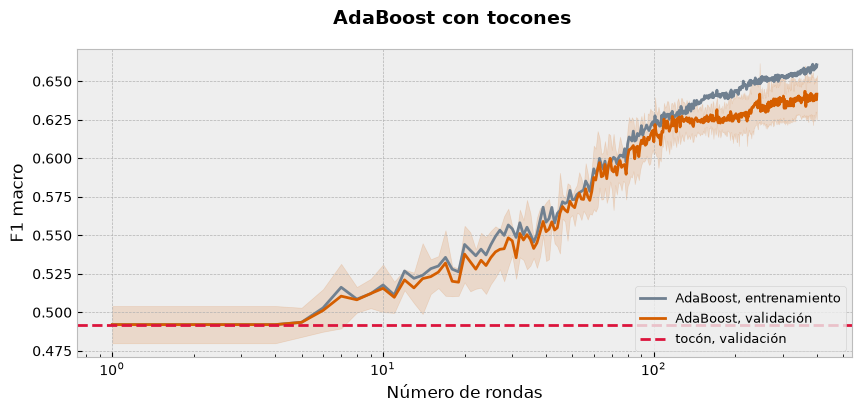

Mejor F1 macro de validación: 0.643, en la ronda 361


,F1 macro,desv. est.,F1 entrenamiento,sensibilidad enrolled,entrenamiento (s)
Tocón,0.492,0.012,0.492,0.000,0.021
AdaBoost,0.642,0.012,0.661,0.266,3.473


In [6]:
tocon = pipeline_arbol(max_depth=1)
adaboost = Pipeline([('prep', preparar('passthrough')),
                     ('modelo', AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=400,
                                                   random_state=ran))])

def curvas(crear):
    # F1 macro después de cada ronda (staged_predict), promedio de los 5 pliegues: (entrenamiento, validación)
    entr, val = [], []
    for a, b in pliegues.split(X, y):
        m = crear().fit(X.iloc[a], y.iloc[a])
        Za, Zb = m[:-1].transform(X.iloc[a]), m[:-1].transform(X.iloc[b])   # el preprocesamiento ya ajustado
        entr.append([f1_score(y.iloc[a], p, average='macro') for p in m[-1].staged_predict(Za)])
        val.append([f1_score(y.iloc[b], p, average='macro') for p in m[-1].staged_predict(Zb)])
    L = min(len(v) for v in val)
    return np.array([t[:L] for t in entr]), np.array([v[:L] for v in val])

ada_entr, ada_val = curvas(lambda: clone(adaboost))
resultados['Tocón'] = evaluar(tocon, 'max_depth=1')
resultados['AdaBoost'] = evaluar(adaboost, '400 tocones, learning_rate=1')

rondas = np.arange(1, ada_val.shape[1] + 1)
with plt.style.context('bmh'):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(rondas, ada_entr.mean(axis=0), color='slategrey', label='AdaBoost, entrenamiento')
    ax.plot(rondas, ada_val.mean(axis=0), color='#D55E00', linewidth=2, label='AdaBoost, validación')
    ax.fill_between(rondas, ada_val.mean(axis=0) - ada_val.std(axis=0), ada_val.mean(axis=0) + ada_val.std(axis=0),
                    color='#D55E00', alpha=0.15)
    ax.axhline(resultados['Tocón']['F1 macro'], color='crimson', linestyle='--', label='tocón, validación')
    ax.set_xscale('log')
    ax.set_xlabel('Número de rondas')
    ax.set_ylabel('F1 macro')
    ax.legend(loc='lower right', fontsize=9)
    fig.suptitle('AdaBoost con tocones', fontweight='bold', fontsize=14)
    plt.show()

print(f"Mejor F1 macro de validación: {ada_val.mean(axis=0).max():.3f}, en la ronda {ada_val.mean(axis=0).argmax() + 1}")
tabla(['Tocón', 'AdaBoost'])

El tocón obtiene el mismo F1 macro en entrenamiento y en validación (0.492): no sobreajusta, pero una sola pregunta no alcanza para separar las tres clases, y nunca predice enrolled. AdaBoost no cambia en las primeras rondas y después mejora de forma sostenida hasta 0.642 con 400 rondas. Las curvas de entrenamiento y de validación suben juntas y se mantienen cercanas, lo que indica que boosting reduce el sesgo: cada ronda aumenta el peso de los estudiantes mal clasificados, el siguiente tocón se concentra en ellos, y la suma ponderada de tocones forma una frontera que ningún tocón puede representar por sí solo. La curva sigue subiendo al final, por lo que más rondas aún podrían mejorarlo, aunque la sensibilidad de enrolled (0.266) sigue siendo baja.

## 4. Combinación de los cinco modelos base

Combinar solo ayuda si los modelos se equivocan en casos distintos. Con las predicciones de validación de la sección 1 se cuenta en cuántos estudiantes fallan los cinco a la vez, cuántos serían si sus errores fueran independientes, y la correlación de sus errores entre pares:

In [7]:
mal = pd.DataFrame({m: resultados[m]['pred'] != y.to_numpy() for m in modelos_base})
aciertos = 1 - mal.mean()
print(f"Fallan los cinco en {mal.all(axis=1).sum()} estudiantes ({mal.all(axis=1).mean():.1%}); "
      f"si sus errores fueran independientes, en {np.prod(1 - aciertos) * len(mal):.1f} ({np.prod(1 - aciertos):.1%})")
print(f"Aciertan los cinco en {(~mal).all(axis=1).sum()} ({(~mal).all(axis=1).mean():.1%}); "
      f"si fueran independientes, en {np.prod(aciertos):.1%}")
correlacion = mal.astype(float).corr()
print(f"Correlación media de los errores entre pares: {correlacion.to_numpy()[np.triu_indices(5, 1)].mean():.2f}")
correlacion.round(2)

Fallan los cinco en 425 estudiantes (12.0%); si sus errores fueran independientes, en 9.0 (0.3%)
Aciertan los cinco en 1639 (46.3%); si fueran independientes, en 16.4%
Correlación media de los errores entre pares: 0.53


,Árbol de decisión,Naive Bayes,kNN,SVM,Regresión logística
Árbol de decisión,1.00,0.46,0.39,0.57,0.55
Naive Bayes,0.46,1.00,0.48,0.56,0.58
kNN,0.39,0.48,1.00,0.46,0.44
SVM,0.57,0.56,0.46,1.00,0.82
Regresión logística,0.55,0.58,0.44,0.82,1.00


Los cinco modelos fallan a la vez en 425 estudiantes (12.0%), cuando con errores independientes serían alrededor de 9, y aciertan juntos en 46.3% de los casos, contra 16.4%. La correlación media de los errores es de 0.53. El par más correlacionado es el SVM con la regresión logística (0.82), que con los mismos atributos estandarizados trazan fronteras parecidas, y el menos correlacionado es el árbol con kNN (0.39). Esto implica que gran parte de los errores corresponde a estudiantes difíciles para cualquier modelo, sobre todo inscritos que se parecen a desertores o a graduados. Una combinación solo puede corregir los casos en los que los modelos discrepan, por lo que la ganancia esperada es pequeña.

Se combinan los cinco con votación dura, votación suave y *stacking* con un meta-modelo logístico. La votación suave y el *stacking* necesitan probabilidades: las del SVM se obtienen con `CalibratedClassifierCV`, que forma parte del *pipeline* y, por lo tanto, se calibra dentro de cada partición de entrenamiento. El *stacking* entrena su meta-modelo con predicciones fuera del pliegue (`cv=5`) y se evalúa con `cross_validate` en los mismos cinco pliegues:

In [8]:
svm_calibrado = Pipeline([('prep', preparar(StandardScaler())),
                          ('modelo', CalibratedClassifierCV(SVC(random_state=ran, **config_p3['SVM']), ensemble=False, cv=5))])
con_probas = dict(modelos_base, SVM=svm_calibrado)

combinaciones = {
    'Votación dura': VotingClassifier(list(modelos_base.items()), voting='hard'),
    'Votación suave': VotingClassifier(list(con_probas.items()), voting='soft'),
    'Stacking': StackingClassifier(list(con_probas.items()), final_estimator=LogisticRegression(max_iter=5000), cv=5),
}
for nombre, modelo in combinaciones.items():
    resultados[nombre] = evaluar(modelo, 'los cinco base' + (', meta-modelo logístico' if nombre == 'Stacking' else ''))
tabla(['SVM', 'Regresión logística'] + list(combinaciones))

,F1 macro,desv. est.,F1 entrenamiento,sensibilidad enrolled,entrenamiento (s)
SVM,0.683,0.008,0.736,0.609,0.561
Regresión logística,0.682,0.010,0.709,0.570,0.399
Votación dura,0.689,0.009,0.739,0.553,0.751
Votación suave,0.675,0.008,0.734,0.435,1.971
Stacking,0.673,0.009,0.721,0.362,9.889


La votación dura (0.689) es la única combinación que supera al SVM, por 0.006, una diferencia menor que la desviación estándar entre pliegues. La votación suave (0.675) y el stacking (0.673) quedan por debajo del SVM y de la regresión logística. La diferencia está en la clase enrolled: la votación dura conserva las decisiones de los modelos con pesos por clase y reconoce a 55% de los inscritos, mientras que al promediar probabilidades, y en especial con el meta-modelo logístico sin pesos por clase, las probabilidades de enrolled quedan por debajo de las de las clases mayoritarias, y la sensibilidad baja a 0.435 y a 0.362. Además, el stacking tarda unos 10 s por entrenamiento, treinta veces más que el SVM solo.

## 5. Bagging optimizado

Random Forest y Extra-Trees se optimizan con `RandomizedSearchCV`, con 50 configuraciones cada uno sobre los mismos pliegues. Ambos usan 400 árboles, el máximo de la curva de la sección 2. Se grafica el F1 macro de cada configuración y el mejor alcanzado hasta ese momento, en el orden en que se evaluaron:

In [9]:
N_CONFIG = 50
N_ARBOLES_ENSAMBLE = 400
TOLERANCIA = 0.005
colores = {'Random Forest': '#467821', 'Extra-Trees': '#7A68A6', 'LightGBM': '#348ABD', 'CatBoost': '#D55E00'}

def meseta(nombre, valores):
    # F1 macro de cada configuración y el mejor alcanzado hasta ese momento, contra el número de configuraciones evaluadas
    mejor = np.maximum.accumulate(valores)
    n = np.arange(1, len(valores) + 1)
    n_meseta = int(np.argmax(mejor >= mejor[-1] - TOLERANCIA)) + 1
    piso = max(valores.min(), mejor[-1] - 0.12) - 0.005
    with plt.style.context('bmh'):
        fig, ax = plt.subplots(figsize=(10, 3.6))
        ax.scatter(n, valores, s=16, color='slategrey', alpha=0.5, label='configuración')
        ax.step(n, mejor, where='post', color=colores.get(nombre, '#348ABD'), linewidth=2.2, label='mejor hasta el momento')
        ax.axvline(n_meseta, color='black', linestyle='--', linewidth=1)
        ax.text(n_meseta + 0.6, mejor[-1] + 0.004, f'configuración {n_meseta}', fontsize=9)
        ax.set_ylim(piso, mejor[-1] + 0.015)
        ax.set_xlabel('Configuraciones evaluadas')
        ax.set_ylabel('F1 macro de validación')
        ax.legend(loc='lower right', fontsize=9)
        fig.suptitle(f'Convergencia de la búsqueda | {nombre} (el eje no inicia en 0)', fontweight='bold', fontsize=13)
        plt.show()

busquedas = {}

def buscar(nombre, modelo, distribuciones):
    busqueda = RandomizedSearchCV(modelo, distribuciones, n_iter=N_CONFIG, scoring='f1_macro', cv=pliegues,
                                  random_state=ran, n_jobs=-1, refit=False)
    t0 = perf_counter()
    busqueda.fit(X, y)
    tiempo = perf_counter() - t0
    busquedas[nombre] = busqueda
    mejor = busqueda.best_params_
    resultados[nombre] = evaluar(clone(modelo).set_params(**mejor), formato(mejor))
    resultados[nombre]['búsqueda (s)'] = tiempo
    print(f"{N_CONFIG} configuraciones en {tiempo:.0f} s | mejor F1 macro: {busqueda.best_score_:.3f} "
          f"(configuración {busqueda.best_index_ + 1})")
    print("Mejor configuración:", formato(mejor))
    meseta(nombre, busqueda.cv_results_['mean_test_score'])

### 5.1. Random Forest

50 configuraciones en 56 s | mejor F1 macro: 0.684 (configuración 25)
Mejor configuración: class_weight=balanced_subsample, criterion=log_loss, max_depth=None, max_features=0.1, min_samples_leaf=5


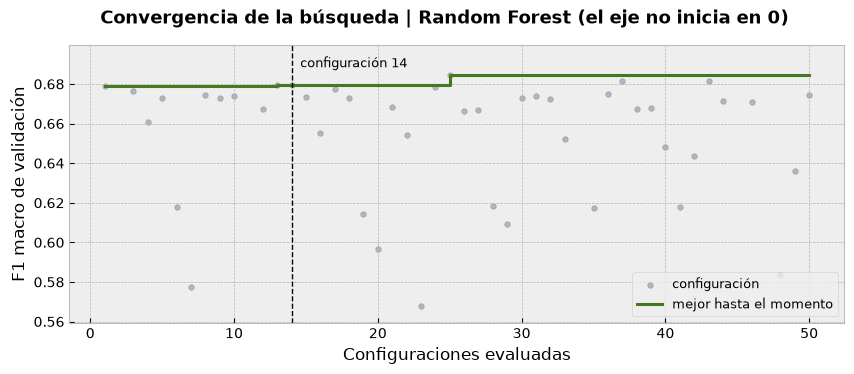

In [10]:
bosque = Pipeline([('prep', preparar('passthrough')),
                   ('modelo', RandomForestClassifier(n_estimators=N_ARBOLES_ENSAMBLE, random_state=ran, n_jobs=1))])
espacio_rf = {
    'modelo__max_features': ['sqrt', 'log2', 0.1, 0.2, 0.3, 0.5],
    'modelo__min_samples_leaf': randint(1, 31),
    'modelo__max_depth': [None, 10, 20, 30],
    'modelo__criterion': ['gini', 'entropy', 'log_loss'],
    'modelo__class_weight': [None, 'balanced', 'balanced_subsample'],
}
buscar('Random Forest', bosque, espacio_rf)

La mejor configuración (0.684) aparece en la configuración 25, pero desde la primera ya se estaba a menos de 0.005 de ella, de modo que la búsqueda alcanza la meseta de inmediato. Las cinco mejores configuraciones usan pesos por clase balanced_subsample, y las peores (alrededor de 0.52) no usan pesos por clase, por lo que este es el hiperparámetro decisivo; el resto mueve poco el resultado. Frente a bagging (0.661), el bosque gana 0.023 al considerar solo 10% de los atributos en cada división, lo que hace a los árboles menos parecidos entre sí, y con hojas de al menos 5 estudiantes, que suavizan cada árbol (F1 de entrenamiento de 0.855 en lugar de 1).

### 5.2. Extra-Trees

50 configuraciones en 51 s | mejor F1 macro: 0.670 (configuración 26)
Mejor configuración: bootstrap=True, class_weight=balanced, criterion=log_loss, max_depth=20, max_features=0.5, min_samples_leaf=7


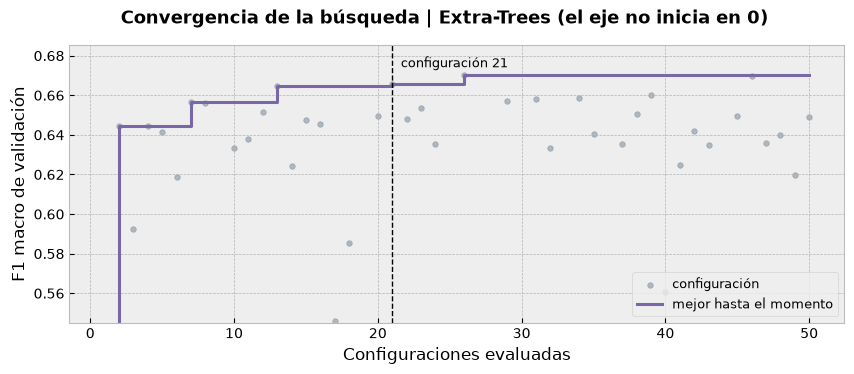

In [11]:
extra = Pipeline([('prep', preparar('passthrough')),
                  ('modelo', ExtraTreesClassifier(n_estimators=N_ARBOLES_ENSAMBLE, random_state=ran, n_jobs=1))])
espacio_et = dict(espacio_rf, modelo__bootstrap=[True, False])
buscar('Extra-Trees', extra, espacio_et)

Extra-Trees alcanza 0.670, en la configuración 26, y la meseta se alcanza en la configuración 21. Queda 0.014 por debajo de Random Forest: los umbrales aleatorios hacen a los árboles aún más distintos entre sí, pero también menos precisos, y en este problema el sesgo agregado pesa más que la varianza que se elimina. Las mejores configuraciones consideran más atributos por división (30 a 50%), lo que compensa en parte la aleatoriedad de los umbrales. Igual que en el bosque, las configuraciones sin pesos por clase son las peores (alrededor de 0.50).

## 6. Boosting optimizado

Se optimizan LightGBM y CatBoost con el mismo procedimiento, también con 400 árboles. En ambos se buscan la tasa de aprendizaje, una regularización de las hojas, el submuestreo de filas y de columnas, y los pesos por clase:

### 6.1. LightGBM

50 configuraciones en 28 s | mejor F1 macro: 0.686 (configuración 3)
Mejor configuración: class_weight=balanced, colsample_bytree=0.899, learning_rate=0.0206, min_child_samples=25, num_leaves=40, reg_lambda=0.0165, subsample=0.762


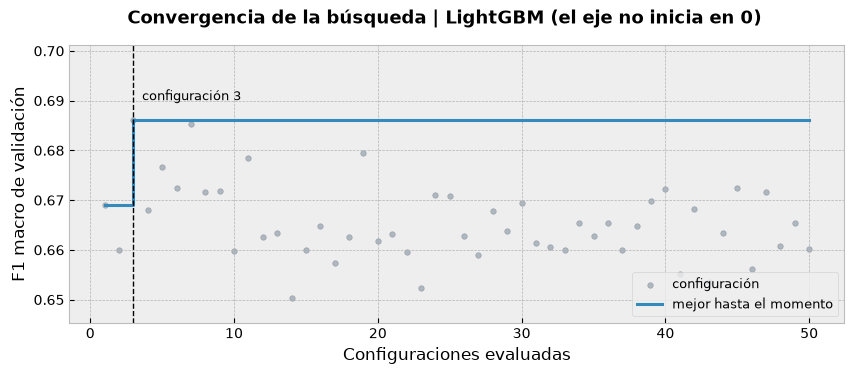

In [12]:
lgbm = Pipeline([('prep', preparar('passthrough')),
                 ('modelo', LGBMClassifier(n_estimators=N_ARBOLES_ENSAMBLE, subsample_freq=1, random_state=ran,
                                           n_jobs=1, verbose=-1))])
espacio_lgbm = {
    'modelo__learning_rate': loguniform(0.01, 0.3),
    'modelo__num_leaves': randint(8, 65),
    'modelo__min_child_samples': randint(5, 61),
    'modelo__reg_lambda': loguniform(1e-3, 10),
    'modelo__subsample': uniform(0.5, 0.5),
    'modelo__colsample_bytree': uniform(0.4, 0.6),
    'modelo__class_weight': [None, 'balanced'],
}
buscar('LightGBM', lgbm, espacio_lgbm)

La mejor configuración (0.686) aparece en la tercera y ninguna de las siguientes la supera. El rango de resultados es mucho más estrecho que en los bosques (de 0.650 a 0.686), por lo que LightGBM depende poco de los hiperparámetros en este espacio. Las cinco mejores configuraciones combinan pesos por clase balanced con tasas de aprendizaje bajas (0.014 a 0.030), y las peores, tasas altas sin pesos por clase. Con 400 árboles de 40 hojas, el F1 de entrenamiento llega a 0.990, sin que la validación se deteriore, aunque su desviación estándar entre pliegues (0.019) es la mayor de los modelos optimizados.

### 6.2. CatBoost

50 configuraciones en 95 s | mejor F1 macro: 0.688 (configuración 41)
Mejor configuración: auto_class_weights=Balanced, depth=4, l2_leaf_reg=5.22, learning_rate=0.046, rsm=0.997, subsample=0.588


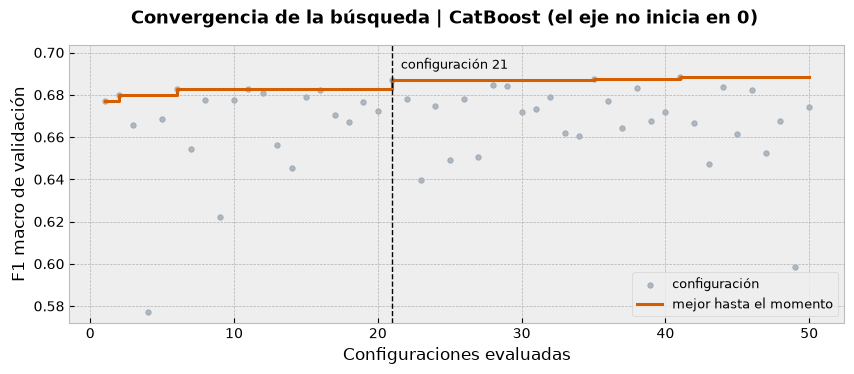

In [13]:
cat = Pipeline([('prep', preparar('passthrough')),
                ('modelo', CatBoostClassifier(iterations=N_ARBOLES_ENSAMBLE, bootstrap_type='Bernoulli', random_seed=ran,
                                              thread_count=1, verbose=0, allow_writing_files=False))])
espacio_cat = {
    'modelo__learning_rate': loguniform(0.01, 0.3),
    'modelo__depth': randint(3, 9),
    'modelo__l2_leaf_reg': loguniform(1, 30),
    'modelo__subsample': uniform(0.5, 0.5),
    'modelo__rsm': uniform(0.4, 0.6),
    'modelo__auto_class_weights': ['None', 'Balanced', 'SqrtBalanced'],  # 'None' como texto: con None, clone() de scikit-learn falla
}
buscar('CatBoost', cat, espacio_cat)

CatBoost alcanza 0.688 en la configuración 41, aunque desde la 21 ya estaba a menos de 0.005 de ese valor. Las cinco mejores configuraciones usan pesos por clase Balanced, y las cuatro peores (de 0.577 a 0.640) no usan pesos por clase. La mejor configuración usa árboles poco profundos (profundidad 4) con una tasa de aprendizaje de 0.046. A diferencia de LightGBM, su F1 de entrenamiento (0.756) queda cerca del de validación: los árboles simétricos y la regularización de las hojas limitan cuánto memoriza cada árbol, y la desviación entre pliegues (0.011) es menor. Además, reconoce a 60% de los inscritos, la sensibilidad de enrolled más alta entre los ensambles, y entrena en 0.65 s por pliegue, menos que LightGBM y Random Forest.

## 7. Comparación de todos los modelos

Todos los modelos se ordenan por su F1 macro de validación, con la desviación estándar entre pliegues, la sensibilidad de la clase enrolled, el tiempo promedio de entrenamiento por pliegue y, en los optimizados, el tiempo de la búsqueda y la mejor configuración:

In [14]:
comparacion = pd.DataFrame(resultados).T.drop(columns=['pred'])
comparacion = comparacion[['F1 macro', 'desv. est.', 'sensibilidad enrolled', 'entrenamiento (s)', 'búsqueda (s)', 'configuración']]
comparacion = comparacion.sort_values('F1 macro', ascending=False)
pd.set_option('display.max_colwidth', None)
comparacion.style.format({'F1 macro': '{:.3f}', 'desv. est.': '{:.3f}', 'sensibilidad enrolled': '{:.3f}',
                          'entrenamiento (s)': '{:.2f}', 'búsqueda (s)': '{:.0f}'}, na_rep='')

,F1 macro,desv. est.,sensibilidad enrolled,entrenamiento (s),búsqueda (s),configuración
Votación dura,0.689,0.009,0.553,0.75,,los cinco base
CatBoost,0.688,0.011,0.602,1.22,95,"auto_class_weights=Balanced, depth=4, l2_leaf_reg=5.22, learning_rate=0.046, rsm=0.997, subsample=0.588"
LightGBM,0.686,0.019,0.457,1.13,28,"class_weight=balanced, colsample_bytree=0.899, learning_rate=0.0206, min_child_samples=25, num_leaves=40, reg_lambda=0.0165, subsample=0.762"
Random Forest,0.684,0.005,0.482,1.76,56,"class_weight=balanced_subsample, criterion=log_loss, max_depth=None, max_features=0.1, min_samples_leaf=5"
SVM,0.683,0.008,0.609,0.56,,"kernel=rbf, C=10.2, gamma=0.00407, class_weight=balanced"
Regresión logística,0.682,0.010,0.570,0.40,,"C=0.0953, l1_ratio=0.311, class_weight=balanced"
Votación suave,0.675,0.008,0.435,1.97,,los cinco base
Stacking,0.673,0.009,0.362,9.89,,"los cinco base, meta-modelo logístico"
Extra-Trees,0.670,0.008,0.537,2.88,51,"bootstrap=True, class_weight=balanced, criterion=log_loss, max_depth=20, max_features=0.5, min_samples_leaf=7"
Bagging,0.661,0.026,0.326,1.14,,400 árboles sin límite


Los seis primeros lugares quedan dentro de 0.007 de F1 macro (de 0.682 a 0.689), una diferencia del orden de la desviación estándar entre pliegues. La votación dura ocupa el primer lugar, seguida muy de cerca por CatBoost, LightGBM, Random Forest, el SVM y la regresión logística. Es decir, sobre clasificadores base ya bien ajustados, los ensambles aportan poco: el límite lo pone la información disponible al cierre del primer semestre, no la capacidad del modelo. Los ensambles que no corrigen la debilidad de su modelo base, como bagging sin pesos por clase o AdaBoost con tocones, quedan por debajo del árbol optimizado o a su nivel. En la clase enrolled, el SVM sigue siendo el de mayor sensibilidad (0.609), seguido de CatBoost (0.602) y de la votación dura (0.553), mientras que LightGBM y Random Forest reconocen a menos de la mitad de los inscritos. En costo, el SVM entrena en 0.33 s, contra 0.65 a 1.6 s de los ensambles optimizados, más 2 a 4 minutos de búsqueda, de modo que el SVM solo ofrece prácticamente el mismo desempeño con mucha menor complejidad.

La matriz de confusión del mejor modelo, con sus predicciones de validación cruzada:

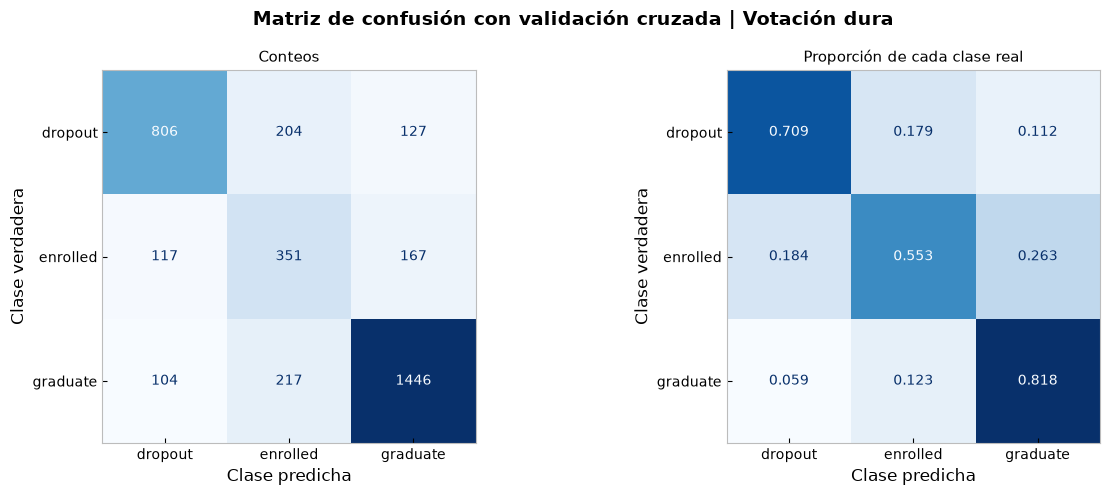

In [15]:
mejor_modelo = comparacion.index[0]
with plt.style.context('bmh'):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, normalizar, titulo, fmt in [(axes[0], None, 'Conteos', 'd'), (axes[1], 'true', 'Proporción de cada clase real', '.3f')]:
        ConfusionMatrixDisplay.from_predictions(y, resultados[mejor_modelo]['pred'], labels=orden_clases, normalize=normalizar,
                                                values_format=fmt, cmap='Blues', colorbar=False, ax=ax)
        ax.set_title(titulo, fontsize=11)
        ax.set_xlabel('Clase predicha')
        ax.set_ylabel('Clase verdadera')
        ax.grid(False)
    fig.suptitle(f'Matriz de confusión con validación cruzada | {mejor_modelo}', fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.show()

La votación dura reconoce a 82% de los graduados y a 71% de los desertores, pero solo a 55% de los inscritos. Los errores se concentran en torno a la clase enrolled: 18% de los inscritos se clasifican como desertores y 26% como graduados, y a su vez 18% de los desertores y 12% de los graduados se clasifican como inscritos. La confusión directa entre desertores y graduados es menor (11% y 6%).

---

## Parte 2. Bank Marketing

## 8. Datos y protocolo

Se utilizan los registros de las campañas telefónicas de un banco portugués de la Tarea 4 (Bank Marketing, de UCI): en cada llamada se ofreció un depósito a plazo, y `y` indica si el cliente lo contrató. Se elimina `duration`, que solo se conoce al terminar la llamada, y la clase se codifica como 1 (yes) y 0 (no):

In [16]:
banco = pd.read_csv('data/bank-additional-full.csv', sep=';')
X_b = banco.drop(columns=['duration', 'y'])
y_b = (banco['y'] == 'yes').astype(int)

cols_cat_b = list(X_b.select_dtypes(exclude='number').columns)
cols_num_b = list(X_b.select_dtypes(include='number').columns)
print(f"{X_b.shape[0]:,} llamadas, {X_b.shape[1]} atributos: {len(cols_cat_b)} categóricos y {len(cols_num_b)} numéricos")
print(f"Contrataron el depósito: {y_b.sum():,} ({y_b.mean():.1%})")

41,188 llamadas, 19 atributos: 10 categóricos y 9 numéricos
Contrataron el depósito: 4,640 (11.3%)


Las clases están muy desbalanceadas: un clasificador que siempre responda no obtiene un F1 macro de 0.47. Cada modelo se evalúa con el protocolo indicado, `cross_validate` con cinco pliegues estratificados y el F1 macro. Todo lo que se ajusta con datos (codificación, escalamiento y umbral) forma parte del modelo, por lo que se ajusta solo con la partición de entrenamiento de cada pliegue. La función `evaluar_banco` registra además la sensibilidad y la precisión de la clase yes, el umbral de decisión y el tiempo de entrenamiento.

In [17]:
pliegues_b = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)

def preparar_b(numericos='passthrough'):
    return ColumnTransformer([('categoricos', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cols_cat_b),
                              ('numericos', numericos, cols_num_b)])

def umbral(modelo):
    # El umbral de decisión que maximiza el F1 macro, elegido con validación cruzada interna y barajada
    return TunedThresholdClassifierCV(modelo, scoring='f1_macro', cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=2026))

resultados_b = {}

def evaluar_banco(nombre, modelo, configuracion=''):
    r = cross_validate(modelo, X_b, y_b, cv=pliegues_b, scoring='f1_macro', return_estimator=True, return_indices=True, n_jobs=-1)
    pred = np.empty(len(y_b), dtype=int)
    for est, i_val in zip(r['estimator'], r['indices']['test']):
        pred[i_val] = np.ravel(est.predict(X_b.iloc[i_val]))
    umbrales = [getattr(est, 'best_threshold_', 0.5) for est in r['estimator']]
    resultados_b[nombre] = {'F1 macro': r['test_score'].mean(), 'desv. est.': r['test_score'].std(),
                            'sensibilidad yes': pred[y_b == 1].mean(), 'precisión yes': y_b.to_numpy()[pred == 1].mean(),
                            'umbral': np.mean(umbrales), 'entrenamiento (s)': r['fit_time'].mean(),
                            'configuración': configuracion, 'pred': pred, 'modelo': modelo}

def tabla_b(nombres):
    columnas = ['F1 macro', 'desv. est.', 'sensibilidad yes', 'precisión yes', 'umbral', 'entrenamiento (s)']
    return pd.DataFrame({n: resultados_b[n] for n in nombres}).T[columnas].astype(float).round(3)

## 9. Búsqueda del mejor modelo

### 9.1. Balanceo de clases

Con el desbalance, el umbral de 0.5 deja fuera a la mayoría de los clientes que sí contratan. Se comparan tres formas de tratarlo en la regresión logística y en LightGBM con su configuración por omisión: no hacer nada, pesos por clase y ajustar el umbral de decisión:

In [18]:
lr_b = Pipeline([('prep', preparar_b(StandardScaler())),
                 ('modelo', LogisticRegression(max_iter=2000, random_state=ran))])
lgbm_b = Pipeline([('prep', preparar_b()), ('modelo', LGBMClassifier(random_state=ran, n_jobs=1, verbose=-1))])

for nombre, modelo in [('Regresión logística', lr_b), ('LightGBM', lgbm_b)]:
    evaluar_banco(f'{nombre}, umbral 0.5', modelo, 'sin balanceo')
    evaluar_banco(f'{nombre}, pesos por clase', clone(modelo).set_params(modelo__class_weight='balanced'), 'class_weight=balanced')
    evaluar_banco(f'{nombre}, umbral ajustado', umbral(modelo), 'umbral ajustado')
tabla_b(resultados_b)

,F1 macro,desv. est.,sensibilidad yes,precisión yes,umbral,entrenamiento (s)
"Regresión logística, umbral 0.5",0.642,0.010,0.228,0.658,0.500,0.442
"Regresión logística, pesos por clase",0.674,0.004,0.629,0.351,0.500,0.524
"Regresión logística, umbral ajustado",0.708,0.005,0.520,0.458,0.234,3.573
"LightGBM, umbral 0.5",0.664,0.006,0.272,0.642,0.500,0.383
"LightGBM, pesos por clase",0.692,0.004,0.628,0.383,0.500,0.405
"LightGBM, umbral ajustado",0.719,0.006,0.539,0.475,0.252,3.764


Con el umbral de 0.5, la regresión logística y LightGBM reconocen apenas a 23% y 27% de los clientes que contratan, con una precisión cercana a 0.65: solo predicen yes cuando la probabilidad estimada es muy alta, y su F1 macro es de 0.642 y 0.664. Los pesos por clase invierten la situación: la sensibilidad sube a 0.63, pero la precisión cae a 0.35 y 0.38, con un F1 macro de 0.674 y 0.692. Esto se debe a que pesar las clases equivale aproximadamente a bajar el umbral hasta la proporción de la clase yes, un punto fijo que no es el que maximiza el F1 macro. El umbral ajustado busca directamente ese punto, que queda alrededor de 0.23 a 0.25, y logra el mejor equilibrio: una sensibilidad de 0.52 a 0.54 con una precisión de 0.46 a 0.48, y un F1 macro de 0.708 y 0.719. LightGBM supera a la regresión logística en las tres variantes.

### 9.2. LightGBM optimizado

Se optimiza LightGBM con el espacio de búsqueda de la sección 6.1, 400 árboles y el umbral ajustado dentro de cada configuración, de modo que la búsqueda elige directamente por el F1 macro que se obtendrá con el mejor umbral. Se evalúan 50 configuraciones sobre los pliegues del protocolo:

50 configuraciones en 248 s | mejor F1 macro: 0.720 (configuración 20)
Mejor configuración: class_weight=None, colsample_bytree=0.446, learning_rate=0.0268, min_child_samples=26, num_leaves=35, reg_lambda=5.23, subsample=0.904


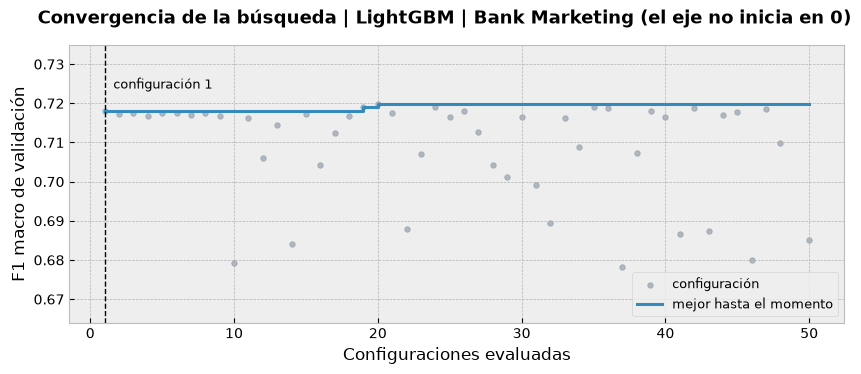

In [19]:
lgbm_umbral = umbral(Pipeline([('prep', preparar_b()),
                               ('modelo', LGBMClassifier(n_estimators=N_ARBOLES_ENSAMBLE, subsample_freq=1, random_state=ran,
                                                         n_jobs=1, verbose=-1))]))
espacio_lgbm_b = {'estimator__' + k: v for k, v in espacio_lgbm.items()}

busqueda_b = RandomizedSearchCV(lgbm_umbral, espacio_lgbm_b, n_iter=N_CONFIG, scoring='f1_macro', cv=pliegues_b,
                                random_state=ran, n_jobs=-1, refit=False)
t0 = perf_counter()
busqueda_b.fit(X_b, y_b)
tiempo_b = perf_counter() - t0
mejor_b = busqueda_b.best_params_
print(f"{N_CONFIG} configuraciones en {tiempo_b:.0f} s | mejor F1 macro: {busqueda_b.best_score_:.3f} "
      f"(configuración {busqueda_b.best_index_ + 1})")
print("Mejor configuración:", formato(mejor_b))
meseta('LightGBM | Bank Marketing', busqueda_b.cv_results_['mean_test_score'])

evaluar_banco('LightGBM optimizado', clone(lgbm_umbral).set_params(**mejor_b), formato(mejor_b))
resultados_b['LightGBM optimizado']['búsqueda (s)'] = tiempo_b

La mejor configuración (0.720) aparece en la configuración 20, pero desde la primera ya se estaba a menos de 0.005 de ella, y la mitad de las configuraciones supera 0.716. Las peores (de 0.669 a 0.679) son las de tasas de aprendizaje mayores a 0.2. Las tres mejores no usan pesos por clase, pues con el umbral ajustado resultan redundantes. La ganancia sobre LightGBM con su configuración por omisión y el umbral ajustado es de apenas 0.001, a cambio de 18 minutos de búsqueda: en este problema importa mucho más el umbral que los hiperparámetros.

### 9.3. Otros ensambles

Se evalúan, también con el umbral ajustado, Random Forest y CatBoost con sus mejores configuraciones de la Parte 1 (sin pesos por clase, que el umbral sustituye). CatBoost recibe los atributos categóricos directamente, sin *one-hot*, pues los codifica internamente con estadísticas de la clase calculadas de forma ordenada. Por último, como el mejor modelo de la Parte 1 fue una votación, se combinan con votación suave la regresión logística, LightGBM optimizado y CatBoost, con el umbral ajustado sobre la probabilidad promedio:

In [20]:
bosque_b = Pipeline([('prep', preparar_b()),
                     ('modelo', RandomForestClassifier(n_estimators=N_ARBOLES_ENSAMBLE, criterion='log_loss', max_features=0.1,
                                                       min_samples_leaf=5, random_state=ran, n_jobs=1))])
cat_b = CatBoostClassifier(iterations=N_ARBOLES_ENSAMBLE, depth=4, learning_rate=0.046, l2_leaf_reg=5.2, bootstrap_type='Bernoulli',
                           subsample=0.59, cat_features=tuple(cols_cat_b), random_seed=ran, thread_count=1, verbose=0,
                           allow_writing_files=False)
lgbm_opt_b = clone(lgbm_umbral.estimator).set_params(**{k.replace('estimator__', ''): v for k, v in mejor_b.items()})

evaluar_banco('Random Forest', umbral(bosque_b), 'max_features=0.1, min_samples_leaf=5, criterion=log_loss')
evaluar_banco('CatBoost', umbral(cat_b), 'depth=4, learning_rate=0.046, l2_leaf_reg=5.2, subsample=0.59, categóricos nativos')
evaluar_banco('Votación suave', umbral(VotingClassifier([('logística', lr_b), ('LightGBM', lgbm_opt_b), ('CatBoost', cat_b)],
                                                       voting='soft')),
              'regresión logística, LightGBM optimizado y CatBoost')
tabla_b(['LightGBM optimizado', 'Random Forest', 'CatBoost', 'Votación suave'])

,F1 macro,desv. est.,sensibilidad yes,precisión yes,umbral,entrenamiento (s)
LightGBM optimizado,0.720,0.005,0.545,0.474,0.252,9.419
Random Forest,0.718,0.004,0.545,0.469,0.265,54.016
CatBoost,0.716,0.006,0.538,0.468,0.262,156.396
Votación suave,0.717,0.006,0.550,0.464,0.245,164.787


Random Forest (0.718), la votación suave (0.717) y CatBoost (0.716) quedan a menos de 0.004 de LightGBM optimizado, y ninguno lo supera. La correlación de los errores entre estos modelos va de 0.89 a 0.95, mucho mayor que la de los cinco modelos base de la deserción (0.53): se equivocan prácticamente con los mismos clientes, por lo que la votación no tiene desacuerdos que corregir. Tampoco ayuda que CatBoost reciba los atributos categóricos sin one hot. Además, estos tres modelos tardan entre 40 y 80 s por pliegue en entrenar, varias veces más que LightGBM

## 10. Comparación

Todos los modelos evaluados con el protocolo, ordenados por su F1 macro

In [21]:
comparacion_b = pd.DataFrame(resultados_b).T.drop(columns=['pred', 'modelo'])
comparacion_b = comparacion_b[['F1 macro', 'desv. est.', 'sensibilidad yes', 'precisión yes', 'umbral', 'entrenamiento (s)',
                               'búsqueda (s)', 'configuración']].sort_values('F1 macro', ascending=False)
comparacion_b.style.format({'F1 macro': '{:.3f}', 'desv. est.': '{:.3f}', 'sensibilidad yes': '{:.3f}', 'precisión yes': '{:.3f}',
                            'umbral': '{:.2f}', 'entrenamiento (s)': '{:.2f}', 'búsqueda (s)': '{:.0f}'}, na_rep='')

,F1 macro,desv. est.,sensibilidad yes,precisión yes,umbral,entrenamiento (s),búsqueda (s),configuración
LightGBM optimizado,0.720,0.005,0.545,0.474,0.25,9.42,248,"class_weight=None, colsample_bytree=0.446, learning_rate=0.0268, min_child_samples=26, num_leaves=35, reg_lambda=5.23, subsample=0.904"
"LightGBM, umbral ajustado",0.719,0.006,0.539,0.475,0.25,3.76,,umbral ajustado
Random Forest,0.718,0.004,0.545,0.469,0.27,54.02,,"max_features=0.1, min_samples_leaf=5, criterion=log_loss"
Votación suave,0.717,0.006,0.550,0.464,0.25,164.79,,"regresión logística, LightGBM optimizado y CatBoost"
CatBoost,0.716,0.006,0.537,0.468,0.26,156.40,,"depth=4, learning_rate=0.046, l2_leaf_reg=5.2, subsample=0.59, categóricos nativos"
"Regresión logística, umbral ajustado",0.708,0.005,0.520,0.458,0.23,3.57,,umbral ajustado
"LightGBM, pesos por clase",0.692,0.004,0.628,0.383,0.50,0.41,,class_weight=balanced
"Regresión logística, pesos por clase",0.674,0.004,0.629,0.351,0.50,0.52,,class_weight=balanced
"LightGBM, umbral 0.5",0.664,0.006,0.272,0.642,0.50,0.38,,sin balanceo
"Regresión logística, umbral 0.5",0.642,0.010,0.228,0.658,0.50,0.44,,sin balanceo


Los cinco ensambles con umbral ajustado quedan dentro de 0.004 de F1 macro (de 0.716 a 0.720), y la regresión logística con umbral ajustado, a 0.012 del mejor. El factor decisivo fue el umbral, que subió el F1 macro de la regresión logística de 0.642 a 0.708 y el de LightGBM de 0.664 a 0.719, mientras que la elección del ensamble y de sus hiperparámetros movió el resultado mucho menos. El mejor modelo es LightGBM optimizado , aunque LightGBM con su configuración por omisión y el umbral ajustado obtiene prácticamente lo mismo con la tercera parte del tiempo de entrenamiento

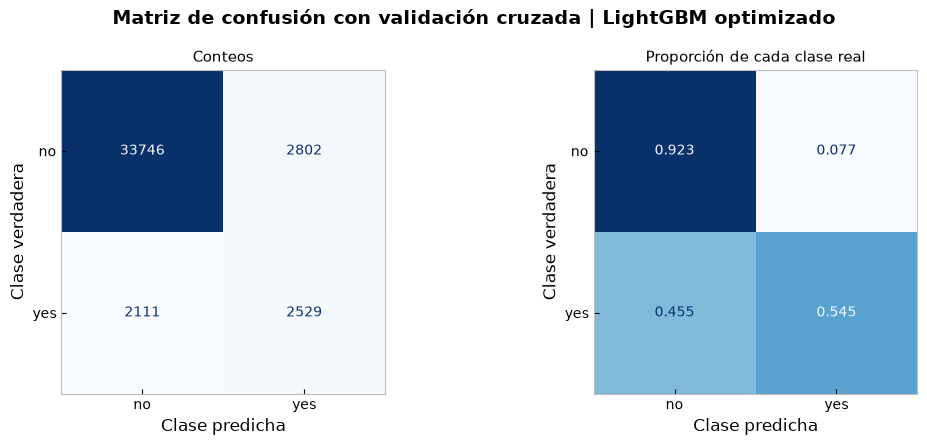

In [22]:
mejor_modelo_b = comparacion_b.index[0]
with plt.style.context('bmh'):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, normalizar, titulo, fmt in [(axes[0], None, 'Conteos', 'd'), (axes[1], 'true', 'Proporción de cada clase real', '.3f')]:
        ConfusionMatrixDisplay.from_predictions(y_b, resultados_b[mejor_modelo_b]['pred'], display_labels=['no', 'yes'],
                                                normalize=normalizar, values_format=fmt, cmap='Blues', colorbar=False, ax=ax)
        ax.set_title(titulo, fontsize=11)
        ax.set_xlabel('Clase predicha')
        ax.set_ylabel('Clase verdadera')
        ax.grid(False)
    fig.suptitle(f'Matriz de confusión con validación cruzada | {mejor_modelo_b}', fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.show()

El modelo detecta a 2,529 de los 4,640 clientes que contratan (55%) y clasifica como yes a 2,802 de los 36,548 que no lo hacen (8%). De cada 100 clientes que predice como yes, 47 contratan, poco más de cuatro veces la proporción de 11% que se obtendría llamando al azar

Lo que funcionó fue parecido a la deserción solo en parte. En ambos problemas los ensambles de árboles quedan arriba y su ventaja sobre el mejor modelo simple es pequeña. Sin embargo, en la deserción ganó la votación, porque los modelos base de distintas familias cometían errores en parte distintos, mientras que aquí los ensambles se equivocan casi con los mismos clientes y combinarlos no aporta. Por otro lado, en Bank Marketing el boosting supera con más claridad al modelo lineal: la respuesta depende de umbrales e interacciones que los árboles representan directamente, mientras que en la deserción la información está concentrada en el desempeño académico, con una relación casi lineal que el SVM y la regresión logística ya aprovechaban. Por último y con dos clases y un desbalance más fuerte, los pesos por clase, que fueron decisivos en la deserción, aquí no bastan, y lo que define el resultado es el umbral de decisión.

## Modelo final

El modelo final es LightGBM optimizado, el mejor de la comparación: el pipeline completo  se entrena con todas las llamadas:

In [28]:
modelo_final = clone(resultados_b[mejor_modelo_b]['modelo']).fit(X_b, y_b)
joblib.dump(modelo_final, "guzman-chaboya_lightgbm.joblib")

cargado = joblib.load("guzman-chaboya_lightgbm.joblib")

In [29]:
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("lightgbm    ", lightgbm.__version__)
print("catboost    ", catboost.__version__)

numpy        2.5.2
pandas       3.0.5
matplotlib   3.11.0
scikit-learn 1.9.0
lightgbm     4.6.0
catboost     1.2.10


## Declaración de Uso de IA Generativa

Para esta práctica se utilizó Claude se utilizó para implementar el ajuste del umbral de decisión dentro del modelo de la segunda parte. También se empleó para corregir errores de compatibilidad entre CatBoost y scikit-learn, para ignorar las llamadas de `warning` particulares a lightgbm y adaboost, y para guardar y verificar el modelo final con `.joblib`. Por último se utilizó para elaborar el archivo `.README` de la práctica.